In [ ]:
!pip install roboflow
!pip install pycocotools
!pip install torchvision


In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key="YKjKJq9jwCbXAUxun5s3")
project = rf.workspace("work-4u6cx").project("yolv5-detection")
version = project.version(4)
dataset = version.download("coco")  # will download to /content/<project-name>


loading Roboflow workspace...
loading Roboflow project...


In [ ]:
import os
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.transforms import functional as F
from torch.utils.data import DataLoader
from pycocotools.coco import COCO
from PIL import Image


In [ ]:
class CustomCocoDataset(torch.utils.data.Dataset):
    def __init__(self, img_dir, ann_file, transforms=None):
        self.img_dir = img_dir
        self.coco = COCO(ann_file)
        self.ids = list(self.coco.imgs.keys())
        self.transforms = transforms

    def __getitem__(self, index):
        img_id = self.ids[index]
        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)
        img_info = self.coco.loadImgs(img_id)[0]
        path = img_info['file_name']

        img = Image.open(os.path.join(self.img_dir, path)).convert("RGB")

        boxes = []
        labels = []
        for ann in anns:
            xmin, ymin, w, h = ann['bbox']
            boxes.append([xmin, ymin, xmin + w, ymin + h])
            labels.append(ann['category_id'])

        target = {
            'boxes': torch.tensor(boxes, dtype=torch.float32),
            'labels': torch.tensor(labels, dtype=torch.int64),
            'image_id': torch.tensor([img_id])
        }

        if self.transforms:
            img = self.transforms(img)

        return img, target

    def __len__(self):
        return len(self.ids)


In [ ]:
!find /content -name "_annotations.coco.json"


/content/YOLV5-Detection-4/valid/_annotations.coco.json
/content/YOLV5-Detection-4/train/_annotations.coco.json
/content/YOLV5-Detection-4/test/_annotations.coco.json


In [ ]:
train_dir = "/content/YOLV5-Detection-4/train"
valid_dir = "/content/YOLV5-Detection-4/valid"

train_dataset = CustomCocoDataset(
    img_dir=train_dir,
    ann_file=os.path.join(train_dir, "_annotations.coco.json"),
    transforms=F.to_tensor
)

val_dataset = CustomCocoDataset(
    img_dir=valid_dir,
    ann_file=os.path.join(valid_dir, "_annotations.coco.json"),
    transforms=F.to_tensor
)

from torch.utils.data import DataLoader
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, collate_fn=lambda x: tuple(zip(*x)))
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, collate_fn=lambda x: tuple(zip(*x)))


loading annotations into memory...
Done (t=0.49s)
creating index...
index created!
loading annotations into memory...
Done (t=0.03s)
creating index...
index created!


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

num_classes = len(train_dataset.coco.getCatIds()) + 1  # +1 for background
model = fasterrcnn_resnet50_fpn(pretrained=True)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(in_features, num_classes)
model.to(device)


The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [ ]:
class CustomCocoDataset(torch.utils.data.Dataset):
    def __init__(self, img_dir, ann_file, transforms=None):
        self.img_dir = img_dir
        self.coco = COCO(ann_file)
        self.ids = list(self.coco.imgs.keys())
        self.transforms = transforms

    def __getitem__(self, index):
        attempts = 0
        while attempts < 10:
            img_id = self.ids[index]
            ann_ids = self.coco.getAnnIds(imgIds=img_id)
            anns = self.coco.loadAnns(ann_ids)
            img_info = self.coco.loadImgs(img_id)[0]
            file_name = img_info["file_name"]
            img_path = os.path.join(self.img_dir, file_name)

            if not os.path.exists(img_path):
                print(f"⚠️ Missing image skipped: {img_path}")
                index = (index + 1) % len(self.ids)
                attempts += 1
                continue

            try:
                img = Image.open(img_path).convert("RGB")
            except:
                print(f"⚠️ Failed to open: {img_path}")
                index = (index + 1) % len(self.ids)
                attempts += 1
                continue

            boxes = []
            labels = []
            for ann in anns:
                xmin, ymin, w, h = ann['bbox']
                boxes.append([xmin, ymin, xmin + w, ymin + h])
                labels.append(ann['category_id'])

            target = {
                'boxes': torch.tensor(boxes, dtype=torch.float32),
                'labels': torch.tensor(labels, dtype=torch.int64),
                'image_id': torch.tensor([img_id])
            }

            if self.transforms:
                img = self.transforms(img)

            return img, target

        raise RuntimeError("Too many consecutive missing or broken images.")

    def __len__(self):
        return len(self.ids)


In [9]:
import torch
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# ✅ Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ✅ Set number of classes (COCO category count + background)
num_classes = len(train_dataset.coco.getCatIds()) + 1

# ✅ Load pretrained Faster R-CNN and replace classification head
model = fasterrcnn_resnet50_fpn(pretrained=True)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
model.to(device)

# ✅ Optimizer and LR scheduler
optimizer = optim.SGD(model.parameters(), lr=0.005, momentum=0.9, weight_decay=0.0005)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=100, gamma=0.1)

# ✅ Training Loop
num_epochs = 300

for epoch in range(num_epochs):
    model.train()
    total_loss = 0.0

    for images, targets in train_loader:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        # Forward pass and loss calculation
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        total_loss += losses.item()

    lr_scheduler.step()

    print(f"✅ Epoch [{epoch+1}/{num_epochs}] - Loss: {total_loss:.4f}")

    # Save model checkpoint every 50 epochs
    if (epoch + 1) % 50 == 0:
        checkpoint_path = f"fasterrcnn_epoch_{epoch+1}.pth"
        torch.save(model.state_dict(), checkpoint_path)
        print(f"📦 Model saved to {checkpoint_path}")

# ✅ Final model save
torch.save(model.state_dict(), "fasterrcnn_final.pth")
print("🎉 Training complete. Final model saved as fasterrcnn_final.pth")


✅ Epoch [1/300] - Loss: 743.8992
✅ Epoch [2/300] - Loss: 551.8051
✅ Epoch [3/300] - Loss: 486.9096
✅ Epoch [4/300] - Loss: 463.2559
✅ Epoch [5/300] - Loss: 425.3621
✅ Epoch [6/300] - Loss: 400.4406
✅ Epoch [7/300] - Loss: 390.1907
✅ Epoch [8/300] - Loss: 381.0956
✅ Epoch [9/300] - Loss: 359.9823
✅ Epoch [10/300] - Loss: 368.6038
✅ Epoch [11/300] - Loss: 348.8880
✅ Epoch [12/300] - Loss: 334.8618
✅ Epoch [13/300] - Loss: 332.7993
✅ Epoch [14/300] - Loss: 321.9819
✅ Epoch [15/300] - Loss: 312.3050
✅ Epoch [16/300] - Loss: 307.0473
✅ Epoch [17/300] - Loss: 308.9800
✅ Epoch [18/300] - Loss: 307.9936
✅ Epoch [19/300] - Loss: 296.7390
✅ Epoch [20/300] - Loss: 285.9930
✅ Epoch [21/300] - Loss: 284.5044
✅ Epoch [22/300] - Loss: 294.7782
✅ Epoch [23/300] - Loss: 267.8322
✅ Epoch [24/300] - Loss: 260.2347
✅ Epoch [25/300] - Loss: 308.8588
✅ Epoch [26/300] - Loss: 278.9838
✅ Epoch [27/300] - Loss: 266.2033
✅ Epoch [28/300] - Loss: 259.3451
✅ Epoch [29/300] - Loss: 248.2469
✅ Epoch [30/300] - Loss

In [10]:
torch.save(model.state_dict(), "fasterrcnn_final.pth")


In [11]:
!pip install scikit-learn
!pip install torchvision


In [12]:
from sklearn.metrics import classification_report
from torchvision.ops import box_iou
import torch

def evaluate_f1_precision_recall(model, data_loader, coco, device, iou_thresh=0.5, conf_thresh=0.5):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, targets in data_loader:
            images = [img.to(device) for img in images]
            outputs = model(images)

            for i in range(len(images)):
                gt_boxes = targets[i]['boxes'].cpu()
                gt_labels = targets[i]['labels'].cpu()
                preds = outputs[i]

                pred_boxes = preds['boxes'].cpu()
                pred_labels = preds['labels'].cpu()
                pred_scores = preds['scores'].cpu()

                # Filter by confidence threshold
                keep = pred_scores >= conf_thresh
                pred_boxes = pred_boxes[keep]
                pred_labels = pred_labels[keep]

                matched_gt = set()

                for j, pred_box in enumerate(pred_boxes):
                    ious = box_iou(pred_box.unsqueeze(0), gt_boxes).squeeze(0)
                    max_iou, max_idx = torch.max(ious, dim=0)

                    if max_iou >= iou_thresh and max_idx.item() not in matched_gt:
                        # Matched
                        y_true.append(gt_labels[max_idx].item())
                        y_pred.append(pred_labels[j].item())
                        matched_gt.add(max_idx.item())
                    else:
                        # False positive
                        y_true.append(-1)  # Background
                        y_pred.append(pred_labels[j].item())

                # False negatives: GT boxes not matched
                for k in range(len(gt_labels)):
                    if k not in matched_gt:
                        y_true.append(gt_labels[k].item())
                        y_pred.append(-1)  # Missed

    # Map category IDs to class names (from COCO)
    cat_id_to_name = {cat['id']: cat['name'] for cat in coco.loadCats(coco.getCatIds())}
    cat_id_to_name[-1] = 'background/missed'

    print("🔍 Classification Report (based on IoU ≥ 0.5 and conf ≥ 0.5):")
    print(classification_report(y_true, y_pred, target_names=[cat_id_to_name[c] for c in sorted(set(y_true + y_pred))]))


In [13]:
from pycocotools.coco import COCO

val_ann_path = os.path.join(valid_dir, "_annotations.coco.json")
coco_gt = COCO(val_ann_path)

evaluate_f1_precision_recall(model, val_loader, coco_gt, device)


loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
🔍 Classification Report (based on IoU ≥ 0.5 and conf ≥ 0.5):
                   precision    recall  f1-score   support

background/missed       0.00      0.00      0.00       579
          Adaptor       0.80      0.58      0.67        48
        Allen Key       1.00      0.83      0.91         6
       Bit Holder       0.00      0.00      0.00         8
      Bit Sockets       0.96      0.87      0.91       601
             Bits       0.80      0.65      0.72       534
      Deep Socket       0.90      0.83      0.87      1981
    Extension Bar       0.82      0.91      0.86       500
      Flex Handle       0.77      0.77      0.77        13
   Rachet-Handels       0.85      0.89      0.87       200
         S Handle       0.00      0.00      0.00         4
          Sockets       0.92      0.91      0.91      3961
         Spanners       1.00      1.00      1.00        12
  long bit socket       0.89 

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


In [14]:
from torchvision.ops import box_iou
import torch

def get_matched_preds(model, data_loader, device, iou_thresh=0.5, conf_thresh=0.5):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, targets in data_loader:
            images = [img.to(device) for img in images]
            outputs = model(images)

            for i in range(len(images)):
                gt_boxes = targets[i]['boxes'].cpu()
                gt_labels = targets[i]['labels'].cpu()
                preds = outputs[i]

                pred_boxes = preds['boxes'].cpu()
                pred_labels = preds['labels'].cpu()
                pred_scores = preds['scores'].cpu()

                # Filter by confidence threshold
                keep = pred_scores >= conf_thresh
                pred_boxes = pred_boxes[keep]
                pred_labels = pred_labels[keep]

                matched_gt = set()

                for j, pred_box in enumerate(pred_boxes):
                    ious = box_iou(pred_box.unsqueeze(0), gt_boxes).squeeze(0)
                    max_iou, max_idx = torch.max(ious, dim=0)

                    if max_iou >= iou_thresh and max_idx.item() not in matched_gt:
                        y_true.append(gt_labels[max_idx].item())
                        y_pred.append(pred_labels[j].item())
                        matched_gt.add(max_idx.item())
                    else:
                        y_true.append(-1)  # False positive
                        y_pred.append(pred_labels[j].item())

                # False negatives
                for k in range(len(gt_labels)):
                    if k not in matched_gt:
                        y_true.append(gt_labels[k].item())
                        y_pred.append(-1)

    return y_true, y_pred


In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

def plot_confusion_matrix(y_true, y_pred, coco):
    # Get category names
    cat_id_to_name = {cat['id']: cat['name'] for cat in coco.loadCats(coco.getCatIds())}
    cat_id_to_name[-1] = 'background/missed'

    labels = sorted(set(y_true + y_pred))
    label_names = [cat_id_to_name[label] for label in labels]

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)

    fig, ax = plt.subplots(figsize=(10, 8))
    disp.plot(include_values=True, xticks_rotation=45, ax=ax, cmap="Blues")
    plt.title("Confusion Matrix (IoU ≥ 0.5, conf ≥ 0.5)")
    plt.tight_layout()
    plt.show()


loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


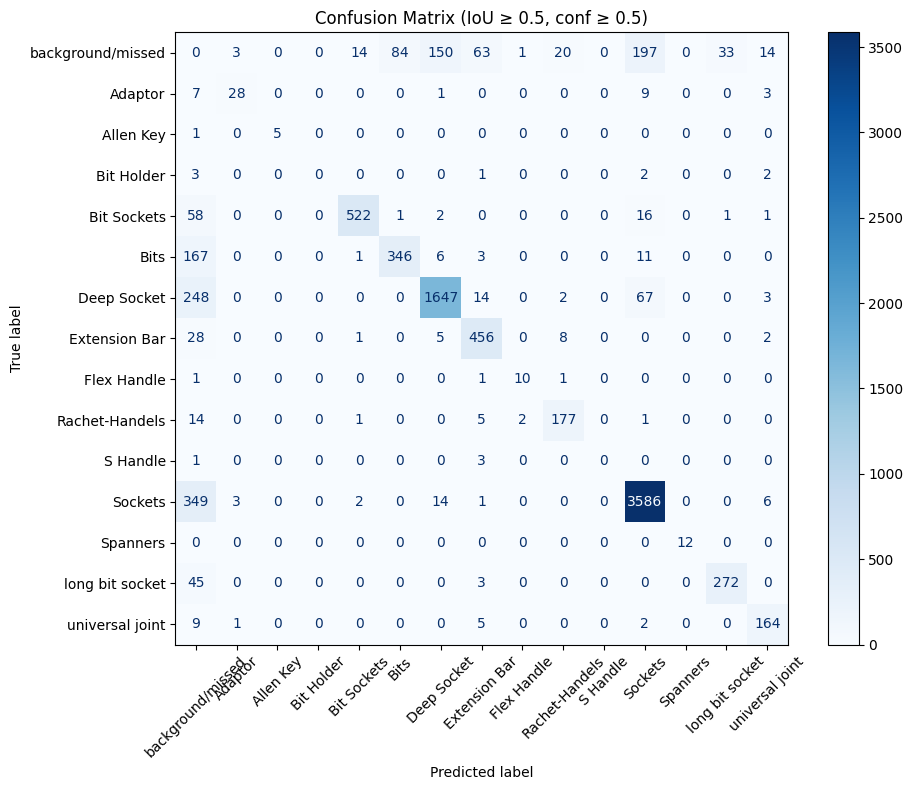

In [16]:
val_ann_path = os.path.join(valid_dir, "_annotations.coco.json")
coco_gt = COCO(val_ann_path)

# Get matched predictions
y_true, y_pred = get_matched_preds(model, val_loader, device)

# Plot confusion matrix
plot_confusion_matrix(y_true, y_pred, coco_gt)
